## Gridding SMAP to 0.1 x 0.1 degree resolution 


In [6]:
import pandas as pd
import numpy as np  
import xarray as xr 
import xesmf as xe
import pyarrow

In [7]:
import sys
print(sys.executable)

/global/home/users/rubypercival/.conda/envs/smap/bin/python


### SMAP 
Gridding SMAP up to 0.1 x 0.1 degree resolution, it was originally at 9km x 9km resolution

In [9]:
WFPS_file = '/global/scratch/users/rubypercival/SMAP24/midwest_soil_moisture_poros_WFPS.parquet'
smap_df=pd.read_parquet(WFPS_file, engine='pyarrow')

In [10]:
smap_df.head()

,latitude,longitude,sm_surface,sm_rootzone,surface_temp,soil_temp_layer1,LAI,datetime_x,catchment_model_porosity,microwave_model_porosity,diff_c-m,WFPS_c,WFPS_m,WFPS_diff
0,48.951267,-103.957474,0.092959,0.115514,282.461212,273.161682,0.042729,2024-02-29 22:28:55,0.3963,0.4351,-0.0388,0.234567,0.213649,0.020917
1,48.951267,-103.864113,0.166994,0.197637,282.129181,273.091370,0.036702,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.383719,0.364298,0.019420
2,48.951267,-103.770752,0.168032,0.197454,281.304840,272.724182,0.030683,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.386103,0.366562,0.019541
3,48.951267,-103.677391,0.166872,0.200200,281.550812,272.728088,0.029180,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.383438,0.364032,0.019406
4,48.951267,-103.584030,0.165163,0.201177,281.975861,272.935120,0.029721,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.379511,0.360304,0.019207


In [11]:
smap_reduced_df = smap_df.drop(columns={'microwave_model_porosity', 'diff_c-m','WFPS_m', 'WFPS_diff'})
smap_reduced_df=smap_reduced_df.rename(columns ={'datetime_x':'datetime'})
smap_reduced_df.head()


,latitude,longitude,sm_surface,sm_rootzone,surface_temp,soil_temp_layer1,LAI,datetime,catchment_model_porosity,WFPS_c
0,48.951267,-103.957474,0.092959,0.115514,282.461212,273.161682,0.042729,2024-02-29 22:28:55,0.3963,0.234567
1,48.951267,-103.864113,0.166994,0.197637,282.129181,273.091370,0.036702,2024-02-29 22:28:55,0.4352,0.383719
2,48.951267,-103.770752,0.168032,0.197454,281.304840,272.724182,0.030683,2024-02-29 22:28:55,0.4352,0.386103
3,48.951267,-103.677391,0.166872,0.200200,281.550812,272.728088,0.029180,2024-02-29 22:28:55,0.4352,0.383438
4,48.951267,-103.584030,0.165163,0.201177,281.975861,272.935120,0.029721,2024-02-29 22:28:55,0.4352,0.379511


In [12]:
smap_reduced_df['datetime'].unique()

<DatetimeArray>
['2024-02-29 22:28:55', '2024-03-01 01:28:55', '2024-03-01 04:28:55',
 '2024-03-01 07:28:55', '2024-03-01 10:28:55', '2024-03-01 13:28:55',
 '2024-03-01 16:28:55', '2024-03-01 19:28:55', '2024-03-01 22:28:55',
 '2024-03-02 01:28:55',
 ...
 '2024-07-30 19:28:55', '2024-07-30 22:28:55', '2024-07-31 01:28:55',
 '2024-07-31 04:28:55', '2024-07-31 07:28:55', '2024-07-31 10:28:55',
 '2024-07-31 13:28:55', '2024-07-31 16:28:55', '2024-07-31 19:28:55',
 '2024-07-31 22:28:55']
Length: 1225, dtype: datetime64[ms]

In [13]:
regridding_df=smap_reduced_df.copy()

In [14]:
regridding_df['lat'] = regridding_df['latitude'].round(5)
regridding_df['lon'] = regridding_df['longitude'].round(5)

#converting to xarray
ds = regridding_df.set_index(['datetime', 'lat', 'lon']).to_xarray()
da = ds[['sm_surface', 'surface_temp', 'soil_temp_layer1', 'LAI','catchment_model_porosity', 'WFPS_c']]

In [15]:
da

<xarray.Dataset> Size: 1GB
Dimensions:                   (datetime: 1225, lat: 136, lon: 257)
Coordinates:
  * datetime                  (datetime) datetime64[ms] 10kB 2024-02-29T22:28...
  * lat                       (lat) float32 544B 36.07 36.16 ... 48.84 48.95
  * lon                       (lon) float32 1kB -104.0 -103.9 ... -80.15 -80.06
Data variables:
    sm_surface                (datetime, lat, lon) float32 171MB 0.145 ... 0....
    surface_temp              (datetime, lat, lon) float32 171MB 288.7 ... 300.1
    soil_temp_layer1          (datetime, lat, lon) float32 171MB 282.5 ... 297.9
    LAI                       (datetime, lat, lon) float32 171MB 0.184 ... 3.405
    catchment_model_porosity  (datetime, lat, lon) float32 171MB 0.4181 ... 0...
    WFPS_c                    (datetime, lat, lon) float32 171MB 0.3469 ... 0...

In [16]:
#input grid (lat/lon already in the DataArray)
ds_in = xr.Dataset({'lat': (['lat'], da.lat.values), 'lon': (['lon'], da.lon.values)})

lat_out = np.arange(36.05, 49.0, 0.1)   
lon_out = np.arange(-103.95, -80, 0.1)  
ds_out = xr.Dataset({'lat': (['lat'], lat_out), 'lon': (['lon'], lon_out)})

In [17]:
regridder = xe.Regridder(ds_in, ds_out, 'conservative')
regridder

[1789576773.332202] [n0081:3708586:0]        cuda_ctx.c:52   UCX  ERROR cuDeviceGetCount(&num_devices) failed: initialization error


xESMF Regridder 
Regridding algorithm:       conservative 
Weight filename:            conservative_136x257_130x240.nc 
Reuse pre-computed weights? False 
Input grid shape:           (136, 257) 
Output grid shape:          (130, 240) 
Periodic in longitude?      False

In [18]:
da_out = regridder(da, keep_attrs=True)

## Plots of original data vs regridded data for each variable:

In [20]:
import matplotlib.pyplot as plt


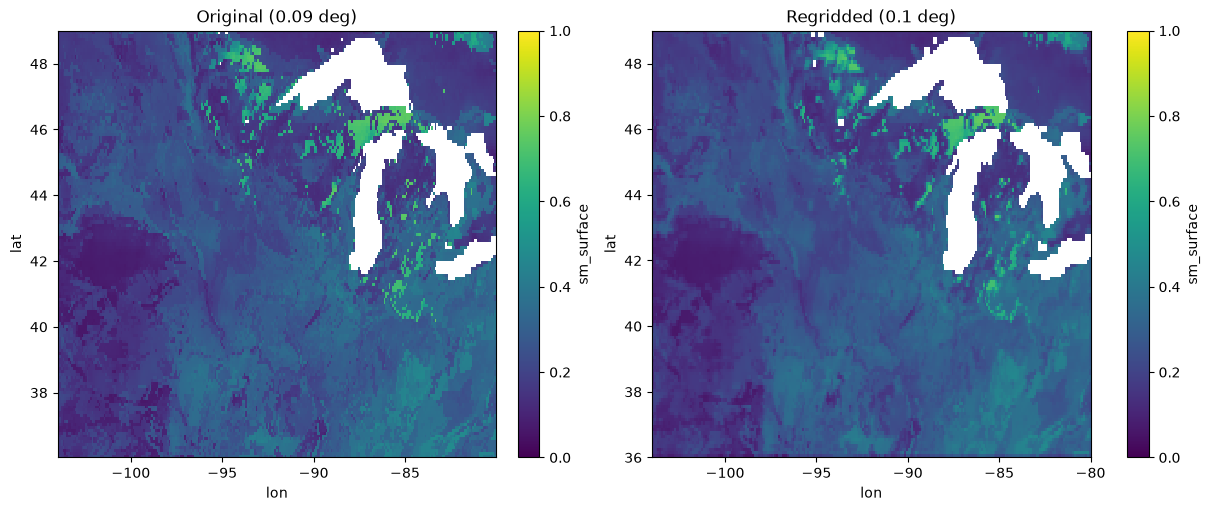

In [21]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 5), constrained_layout=True)

da['sm_surface'].isel(datetime=0).plot(ax=axes[0], vmin=0, vmax=1)
axes[0].set_title("Original (0.09 deg)")

da_out['sm_surface'].isel(datetime=0).plot(ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Regridded (0.1 deg)")

plt.show()

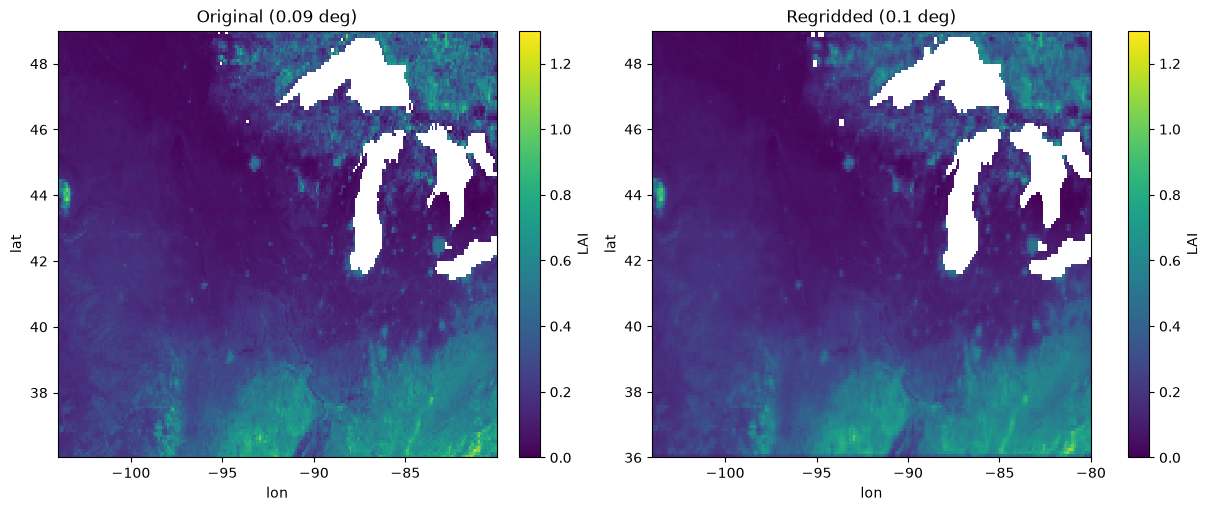

In [22]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 5), constrained_layout=True)

da['LAI'].isel(datetime=0).plot(ax=axes[0], vmin=0, vmax=1.3)
axes[0].set_title("Original (0.09 deg)")

da_out['LAI'].isel(datetime=0).plot(ax=axes[1], vmin=0, vmax=1.3)
axes[1].set_title("Regridded (0.1 deg)")

plt.show()



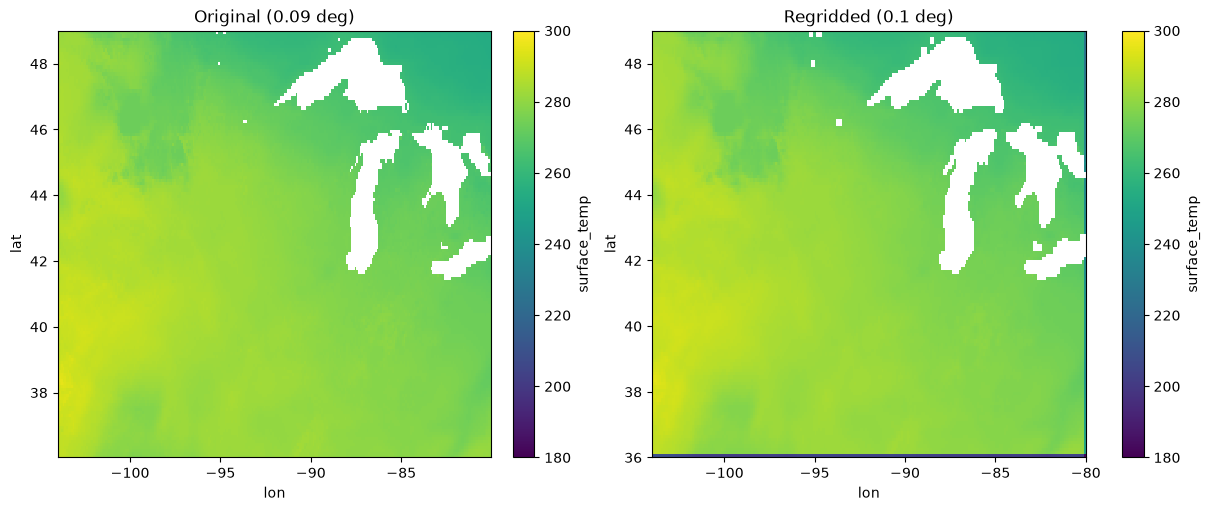

In [23]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 5), constrained_layout=True)

da['surface_temp'].isel(datetime=0).plot(ax=axes[0], vmin=180, vmax=300)
axes[0].set_title("Original (0.09 deg)")

da_out['surface_temp'].isel(datetime=0).plot(ax=axes[1], vmin=180, vmax=300)
axes[1].set_title("Regridded (0.1 deg)")

plt.show()



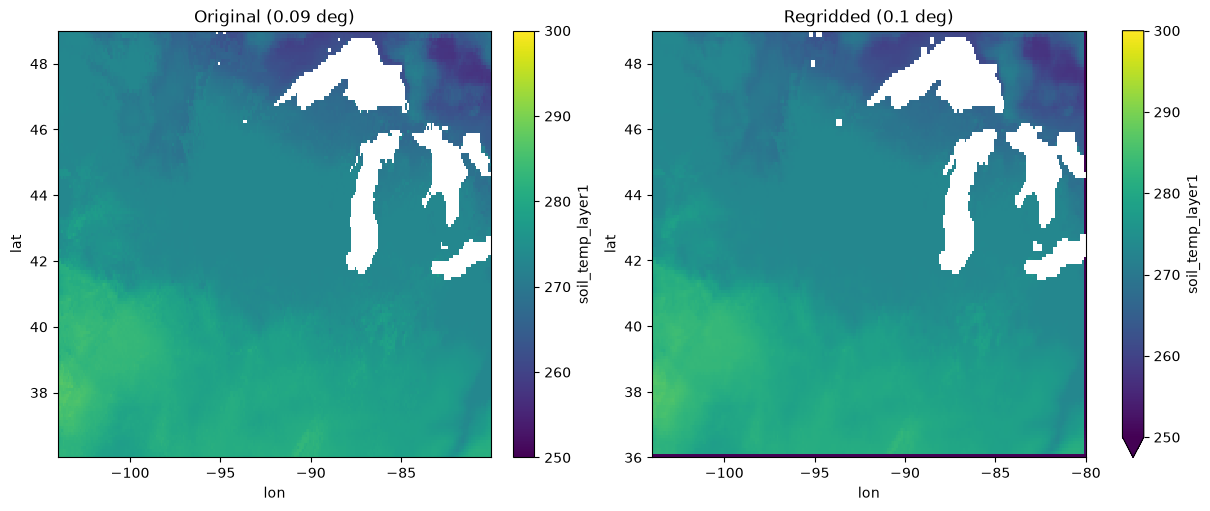

In [24]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 5), constrained_layout=True)

da['soil_temp_layer1'].isel(datetime=0).plot(ax=axes[0], vmin=250, vmax=300)
axes[0].set_title("Original (0.09 deg)")

da_out['soil_temp_layer1'].isel(datetime=0).plot(ax=axes[1], vmin=250, vmax=300)
axes[1].set_title("Regridded (0.1 deg)")

plt.show()

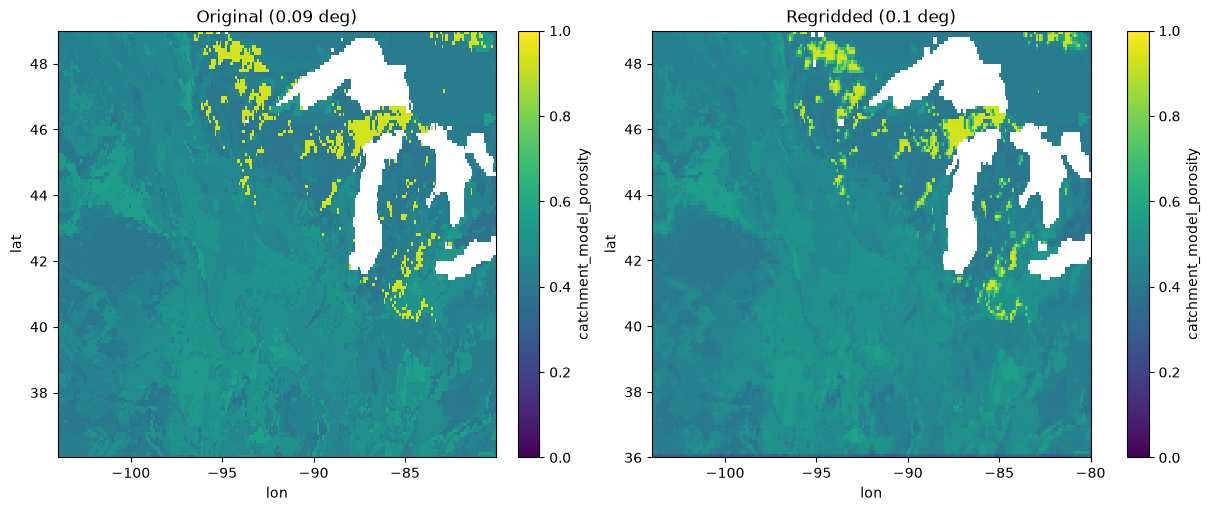

In [25]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 5), constrained_layout=True)

da['catchment_model_porosity'].isel(datetime=0).plot(ax=axes[0], vmin=0, vmax=1)
axes[0].set_title("Original (0.09 deg)")

da_out['catchment_model_porosity'].isel(datetime=0).plot(ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Regridded (0.1 deg)")

plt.show()


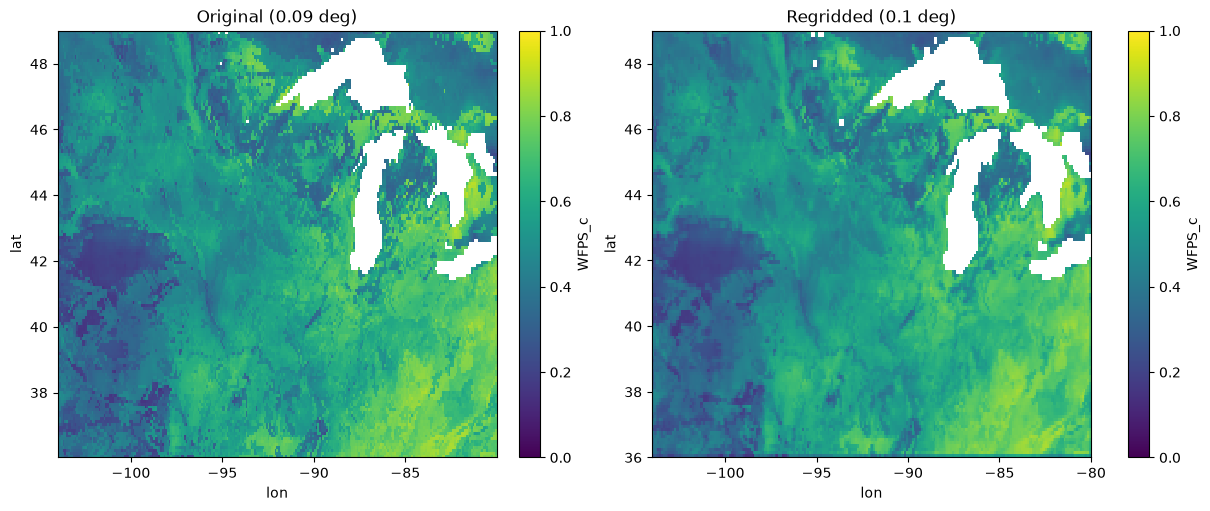

In [26]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 5), constrained_layout=True)

da['WFPS_c'].isel(datetime=0).plot(ax=axes[0], vmin=0, vmax=1)
axes[0].set_title("Original (0.09 deg)")

da_out['WFPS_c'].isel(datetime=0).plot(ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Regridded (0.1 deg)")

plt.show()

## Extracting regridded data as a dataframe --> parquet file

In [27]:
df_regridded = da_out.to_dataframe().reset_index()

In [28]:
{'sm_surface', 'surface_temp','soil_temp_layer1','LAI', 'catchment_model_porosity','WFPS_c'}

{'LAI',
 'WFPS_c',
 'catchment_model_porosity',
 'sm_surface',
 'soil_temp_layer1',
 'surface_temp'}

In [29]:
df_regridded

,datetime,lat,lon,sm_surface,surface_temp,soil_temp_layer1,LAI,catchment_model_porosity,WFPS_c
0,2024-02-29 22:28:55,36.05,-103.95,0.108354,209.426788,204.926285,0.133120,0.305624,0.256903
1,2024-02-29 22:28:55,36.05,-103.85,0.131211,209.389954,204.886414,0.131932,0.322017,0.295457
2,2024-02-29 22:28:55,36.05,-103.75,0.114631,209.313217,204.946014,0.145232,0.308742,0.269316
3,2024-02-29 22:28:55,36.05,-103.65,0.101100,209.129730,204.906342,0.156929,0.303343,0.241807
4,2024-02-29 22:28:55,36.05,-103.55,0.084056,208.797028,204.758514,0.149589,0.297760,0.204821
...,...,...,...,...,...,...,...,...,...
38219995,2024-07-31 22:28:55,48.95,-80.45,0.317019,299.650421,297.236877,3.231190,0.545900,0.580728
38219996,2024-07-31 22:28:55,48.95,-80.35,0.164544,299.994812,297.831024,3.294179,0.401898,0.396976
38219997,2024-07-31 22:28:55,48.95,-80.25,0.126298,300.062225,297.956635,3.220342,0.374100,0.337605
38219998,2024-07-31 22:28:55,48.95,-80.15,0.117489,300.142700,297.919403,3.664984,0.374100,0.314056


In [30]:
output_dir = '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets'
df_regridded.to_parquet(f'{output_dir}/SMAP_LAI_WFPS_0.1x0.1gridded_mar-jul24.parquet',
                        engine='pyarrow')


In [31]:
grid_lon_sorted = np.sort(df_regridded['lon'].unique())
grid_lon_diff = np.diff(grid_lon_sorted)
print(np.unique(np.round(grid_lon_diff, 4)))


[0.1]
